# Trabajo práctico 1: Método de Euler

### Grupo 3
### Gonzalo Díaz Excoffon y Boris Sebastián Rubinstein

---

Dada la siguiente ecuación diferencial ordinaria con su condición inicial:
$$
\begin{cases} 
y' = x^{\frac{3+n}{n}} y, \\
y(0) = 1, 
\end{cases}

\qquad x \in \Omega \quad , \quad \Omega = [0,2] \in \mathbb{R} $$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(x, y):
    return (x**2) * y


---

**Ejercicio 1**
Resolver el problema de manera exacta.

***Resolucion***
Es una ecuación donde se pueden separar las variables, despejando todo lo que depende de $x$ del lado derecho y todo lo que depende de $y$ del lado del izquierdo, integramos, obteniendo lo siguiente:

$$ \ln{ \left\lvert y \right\rvert } = \frac{x^{\frac{3+2n}{n}}}{\frac{3+2n}{n}} + C \qquad$$

Despejando y reutilizando la constante C para la constante K donde $ K = e ^ C$, llegamos a:

$$ y(x) = K e^{\frac{n}{3+ 2n} x^{\frac{3+2n}{n}}}$$

Usando el valor inicial llegamos a que $K = 1$ por lo que la solución de este PVI es, siendo el grupo n = 3:

$$ y(x) = e^{\frac{1}{3} x^3}$$


---

**Ejercicio 2.** Usando valores de $h_1 = 0.2$, $h_2 = 0.1$, $h_3 = 0.01$ construya tres aproximaciones numéricas de la solución mediante el método de Euler y tres aproximaciones utilizando el método de Heun.


***Resolución***
Primero vamos a discretizar el intervalo $[0,2]$ en $ N + 1 $ puntos discretos. De esta forma tenemos que el primer punto discreto le corresponde al $x = 0$ y el último al $x = 2$, con $ N - 1 $ puntos internos entre ambos extremos e iniciando el índice en 0 para utilizar la misma convención de índices que el lenguaje en el que implementamos los métodos numéricos, Python. O sea para $ i = 0$, siendo $i$ el iterador de índices, tenemos el primer punto discreto $x = 0$. En la consigna se piden 3 tamaños de pasos distintos, por lo que se debe discretizar el intervalo de 3 maneras distintas. Siendo $h$ el paso, cada paso resulta ser de $ h = \frac{2}{N}$, observandose en la Tabla 1 cada discretización con los valores resultantes.

$$
\begin{array}{|c|c|c|c|}
\hline
\text{Número de discretización} & \text{Paso } (h) & \text{Cantidad de puntos discretos} \\
\hline
1 & 0.2 & 11  \\
\hline
2 & 0.1 & 21 \\
\hline
3 & 0.01 & 201 \\
\hline
\end{array}
$$
<div align="center"><em>Tabla 1: Valores para la discretización del intervalo.</em></div>


In [3]:
# h es el tamaño del paso
h1 = 0.2
h2 = 0.1
h3 = 0.01

# N + 1 es el número de puntos discretos
N1 = int(2 / h1)
N2 = int(2 / h2)
N3 = int(2 / h3)

# Los distintos pasos generan distintas discretizaciones del intervalo [0, 2]
x1 = np.linspace(0, 2, N1+1)
x2 = np.linspace(0, 2, N2+1)
x3 = np.linspace(0, 2, N3+1)


Una vez discretizado el intervalo, se van a usar las siguientes ecuaciones para el método de **Euler** y el método de **Heun**, Ecuación (1) y Ecuación (2) respectivamente:

$$ y_{i + 1} = y_i + h f(x_i,y_i) \qquad (1)$$

$$ y_{i + 1} = y_i + \frac{h}{2} \left[ f(x_i, y_i) + f(x_{i+1}, y_{i+i}) \right] \qquad (2)$$

El método de Heun es un método implícito, para nuestra suerte, la función a analizar nos permite despejar el valor de $y_{i+1}$ en función de $x_i$, $x_{i+1}$, $y_i$ y $h$, obteniendo la siguiente expresión la cual será implementada en este trabajo:

$$ y_{i+1} = y_i \left[ \frac{1+\frac{h}{2}x_i^2}{1-\frac{h}{2}x_{i+1}^2} \right] \qquad (3) $$

En el resto de este trabajo hablaremos de El método numérico de Euler cuando usemos los resultados de implementar la ecuación (1) en la resolución numérica de nuestro problema; y hablaremos de El método numérico de Heun cuando usemos los resultados de implementar la ecuación (3) en la resolución numérica de nuestro problema.  


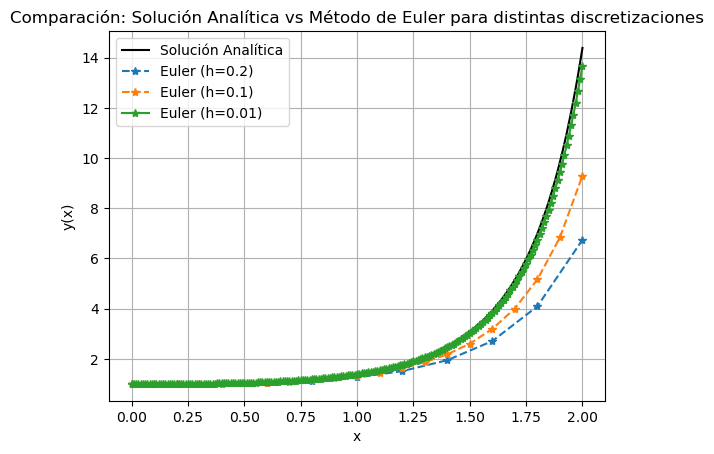

In [4]:
# Creamos los arreglos para almacenar los valores de y en cada paso
y1_E = np.zeros(N1+1)
y2_E = np.zeros(N2+1) 
y3_E = np.zeros(N3+1)

# Imponemos la condición inicial y(0) = 1
y1_E[0] = 1
y2_E[0] = 1
y3_E[0] = 1

# Aplicamos el método de Euler para cada discretización
for i in range(N1):
    y1_E[i + 1] = y1_E[i] + h1 * f(x1[i], y1_E[i])

for i in range(N2):
    y2_E[i + 1] = y2_E[i] + h2 * f(x2[i], y2_E[i])

for i in range(N3):
    y3_E[i + 1] = y3_E[i] + h3 * f(x3[i], y3_E[i])

# Graficamos la solución exacta con las aproximaciones obtenidas con el método de Euler
y_exacta = np.exp((x3**3) / 3)

plt.figure()
plt.title('Comparación: Solución Analítica vs Método de Euler para distintas discretizaciones')
plt.plot(x3, y_exacta, 'k-', label='Solución Analítica')
plt.plot(x1, y1_E, '*--', label='Euler (h=0.2)')
plt.plot(x2, y2_E, '*--', label='Euler (h=0.1)')
plt.plot(x3, y3_E, '*-', label='Euler (h=0.01)')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()

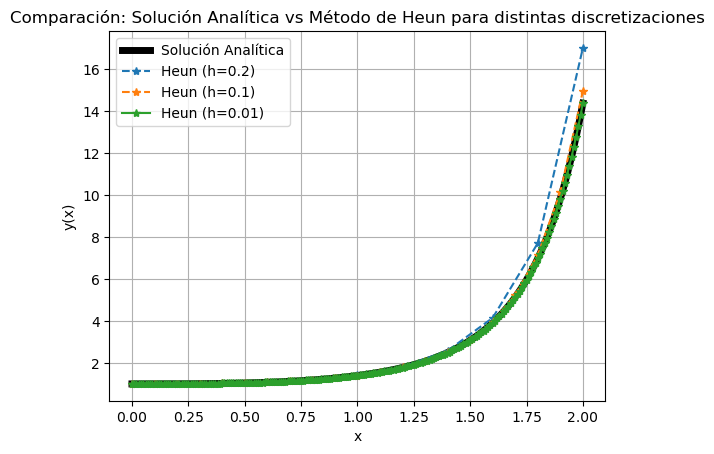

In [5]:
# Ahora, hacemos lo mismo para el método de Heun
y1_H = np.zeros(N1+1)
y2_H = np.zeros(N2+1) 
y3_H = np.zeros(N3+1)

# Imponemos la condición inicial y(0) = 1
y1_H[0] = 1
y2_H[0] = 1
y3_H[0] = 1

# Aplicamos el método de Heun para cada discretización
for i in range(N1):
    y1_H[i + 1] = y1_H[i]*(1 + (h1 / 2) * (x1[i]**2))/(1 - (h1 / 2) * (x1[i+1]**2))
for i in range(N2):
    y2_H[i + 1] = y2_H[i]*(1 + (h2 / 2) * (x2[i]**2))/(1 - (h2 / 2) * (x2[i+1]**2))
for i in range(N3):
    y3_H[i + 1] = y3_H[i]*(1 + (h3 / 2) * (x3[i]**2))/(1 - (h3 / 2) * (x3[i+1]**2))

# Graficamos la solución exacta con las aproximaciones obtenidas con el método de Heun
plt.figure()
plt.title('Comparación: Solución Analítica vs Método de Heun para distintas discretizaciones')
plt.plot(x3, y_exacta, 'k-', linewidth = 5, label='Solución Analítica')
plt.plot(x1, y1_H, '*--', label='Heun (h=0.2)')
plt.plot(x2, y2_H, '*--', label='Heun (h=0.1)')
plt.plot(x3, y3_H, '*-', label='Heun (h=0.01)')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()



---


**Ejercicio 3.** Grafique dos campos de pendientes definidos por la función $f(x,y)$, en el primero de ellos grafique también la solución exacta obtenida analíticamente y las tres aproximaciones obtenidas mediante el método de Euler; en el segundo, grafique, además de la solución exacta, las tres aproximaciones obtenidas mediante el método de Heun.


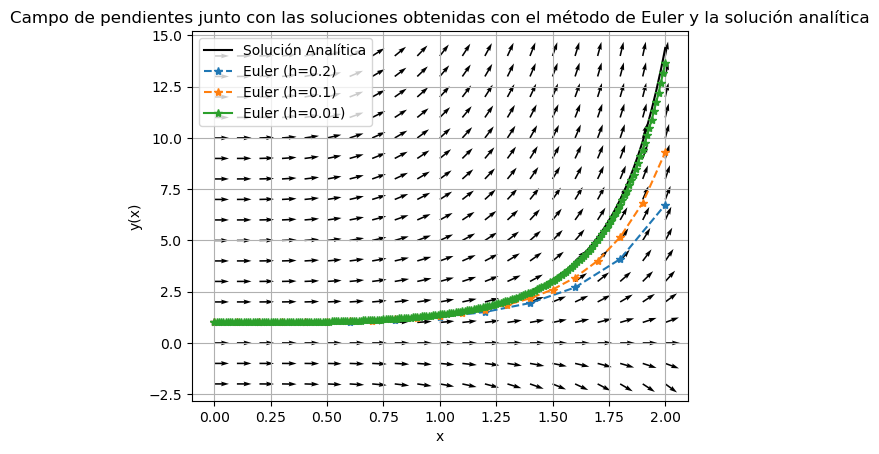

In [6]:
# Creamos la malla para el campo de pendientes
eje_x = np.arange(0, 2.1, 0.1) 
eje_y = np.arange(-2, 15, 1)

malla_X, malla_Y = np.meshgrid(eje_x, eje_y)

# Le damos la orientación a cada vector y lo normalizamos
U = np.ones_like(malla_X) 
V = f(malla_X, malla_Y) 

magnitud = np.sqrt(U**2 + V**2)
U = U/magnitud
V = V/magnitud

# Graficamos el campo de pendientes con la solución analítica y los resultados de Euler
plt.figure()
plt.title('Campo de pendientes junto con las soluciones obtenidas con el método de Euler y la solución analítica')
plt.plot(x3, y_exacta, 'k-', label='Solución Analítica')
plt.plot(x1, y1_E, '*--', label='Euler (h=0.2)')
plt.plot(x2, y2_E, '*--', label='Euler (h=0.1)')
plt.plot(x3, y3_E, '*-', label='Euler (h=0.01)')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.quiver(malla_X, malla_Y, U, V,angles='xy') 
plt.grid(True)

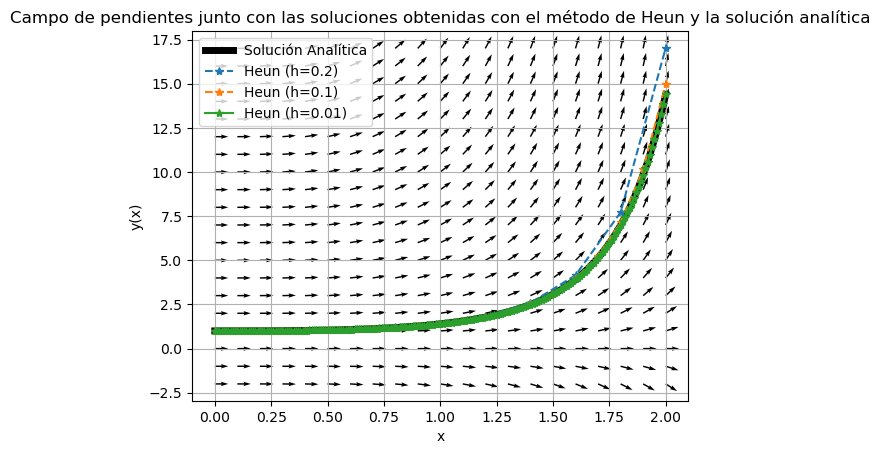

In [7]:
# Creamos la malla para el campo de pendientes
eje_x = np.arange(0, 2.1, 0.1) 
eje_y = np.arange(-2, 18, 1)

malla_X, malla_Y = np.meshgrid(eje_x, eje_y)

# Le damos la orientación a cada vector y lo normalizamos
U = np.ones_like(malla_X) 
V = f(malla_X, malla_Y) 

magnitud = np.sqrt(U**2 + V**2)
U = U/magnitud
V = V/magnitud

# Graficamos el campo de pendientes con la solución analítica y los resultados de Heun
plt.figure()
plt.title('Campo de pendientes junto con las soluciones obtenidas con el método de Heun y la solución analítica')
plt.plot(x3, y_exacta, 'k-',linewidth = 5, label='Solución Analítica')
plt.plot(x1, y1_H, '*--', label='Heun (h=0.2)')
plt.plot(x2, y2_H, '*--', label='Heun (h=0.1)')
plt.plot(x3, y3_H, '*-', label='Heun (h=0.01)')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
# Preguntar al profesor, esto no lo utilizó en sus ejemplos pero en stackoverflow vi que usan esta función.
plt.quiver(malla_X, malla_Y, U, V,angles='xy') 
plt.grid(True)


---

**Ejercicio 4.** Estime el error global de ambos métodos para cada valor de $h$. Para ello, recuerde que para el método de Euler el *error de truncamiento local* en el paso $i$ está dado por

$$\tau := \frac{h^2}{2}y''(\mu) \quad \text{con} \quad \mu \in [x_0 + ih, x_0 + (i+1)h],$$

que para el método de Heun está dado por

$$\tau := \frac{h^3}{6}y'''(\mu) \quad \text{con} \quad \mu \in [x_0 + ih, x_0 + (i+1)h],$$

y que el *error global*, para ambos métodos, verifica la cota

$$|y(x_N) - y_h(x_N)| \le \frac{\tau_{\text{max}}}{Kh}(e^{K(x_N - x_0)} - 1)$$

donde $K$ es la constante de Lipschitz de $f(x,y)$ en la variable $y$ y $\tau_{\text{max}}$ es el máximo de los módulos de los errores de truncamiento local.


***Resolución*** Tomando $ K = f'(x,y)$ y evaluando en el último punto de nuestra discretización llegamos a los resultados que se observan en la Tabla 2:

In [10]:
err_global_euler_1 = ( (10 * (0.2**2) * np.exp(8/3)) / (4 * 0.2) ) * (np.exp(8) - 1)
err_global_euler_2 = ( (10 * (0.1**2) * np.exp(8/3)) / (4 * 0.1) ) * (np.exp(8) - 1)
err_global_euler_3 = ( (10 * (0.01**2) * np.exp(8/3)) / (4 * 0.01) ) * (np.exp(8) - 1)

err_global_heun_1 = ( (19 * (0.2**3) * np.exp(8/3)) / (4 * 0.2) ) * (np.exp(8) - 1)
err_global_heun_2 = ( (19 * (0.1**3) * np.exp(8/3)) / (4 * 0.1) ) * (np.exp(8) - 1)
err_global_heun_3 = ( (19 * (0.01**3) * np.exp(8/3)) / (4 * 0.01) ) * (np.exp(8) - 1)

print(int(err_global_euler_1), int(err_global_euler_2), int(err_global_euler_3))
print(int(err_global_heun_1), int(err_global_heun_2), int(err_global_heun_3))

21443 10721 1072
8148 2037 20


$$
\begin{array}{|c|c|c|}
\hline
\text{Paso } (h) & \text{Error global (Euler)} & \text{Error global (Heun)} \\
\hline
0.2 &  21443 & 8148 \\
\hline
0.1 & 10721 & 2037 \\
\hline
0.01 & 1072 & 20 \\
\hline
\end{array}
$$
<div align="center"><em>Tabla 2: Cotas de error global para los métodos de Euler y Heun según el tamaño del paso.</em></div>

Es importante destacar que esta cota superior tiene una dependencia proporcional a una potencia del tamaño de paso. Para Euler $K_{Euler} \propto h$ mientras que para Heun $K_{Heun} \propto h^2$.


---

**Ejercicio 5.** Compare los errores globales para cada valor de $h$ con las diferencias (en módulo) entre $y(2)$ e $y_h(2)$ (obtenidas en el ítem 1 y 2 respectivamente).

In [14]:
err_real_E1 = abs(y_exacta[-1] - y1_E[-1])
err_real_E2 = abs(y_exacta[-1] - y2_E[-1])
err_real_E3 = abs(y_exacta[-1] - y3_E[-1])

err_real_H1 = abs(y_exacta[-1] - y1_H[-1])
err_real_H2 = abs(y_exacta[-1] - y2_H[-1])
err_real_H3 = abs(y_exacta[-1] - y3_H[-1])

print(err_real_E1, err_real_E2, err_real_E3)
print(err_real_H1, err_real_H2, err_real_H3)



7.648352503029935 5.087826921589764 0.7153477997410107
2.633815933571178 0.5777453023729944 0.0055533415891275695


$$
\begin{array}{|c|c|c|}
\hline
\text{Paso } (h) & \text{Error global (Euler)} & \text{Error global (Heun)} \\
\hline
0.2 & 7.64 & 2.63 \\
\hline
0.1 & 5.08 & 0.57 \\
\hline
0.01 & 0.71 & 0.0055 \\
\hline
\end{array}
$$
<div align="center"><em>Tabla 3: Errores global real para los métodos de Euler y Heun según el tamaño de paso.</em></div>


Comparamos los valores de la Tabla 2 con los valores de la Tabla 3 y observamos que el error real es varios órdenes de magnitud menor a la cota superior. Verificando que la fórmula de cota superior se cumple y que es una cota superior "pesimista" o "conservadora" desde un punto de vista ingenieril para estos métodos. De todos modos, esta fórmula para una cota teórica, resulta más útil con métodos numéricos con un error local que dependen de potencias mayores del paso como Runge-Kutta o Adams-Bashforth.